<a href="https://colab.research.google.com/github/gostek198/podstawy-llm-lab-eiti-pw/blob/main/lab01/lab01_yelp_klasyfikacja_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#LLM - Klasyczne metody klasyfikacji tekstu - LAB

#Zadanie

Zaadaptuj kod z notatnika *LLM - Klasyczne metody klasyfikacji tekstu - Omówienie* do problemu klasyfikacji liczby gwiazdek dla opinii z serwisu Yelp.
Możesz przygotować pętlę treningową albo w czystym PyTorchu, albo z wykorzystaniem biblioteki PyTorch Lightning.

* Wykorzystaj zbiór `Yelp/yelp_review_full` ([link](https://huggingface.co/datasets/Yelp/yelp_review_full)) zawierający opinie z serwisu Yelp (kolumna: `text`) i etykietę (kolumna: `label`) o wartościach $0,1,2,3,4$ określającą liczbę gwiazdek przyznaną przez użytkownika (a ściślej, liczbę gwiazdek minus jeden). Ponieważ mamy pięć klas, ostatnia warstwa liniowa w sieci neuronowej musi zwracać pięć wartości.
    * Zgodnie z dobrą praktyką z części treningowej wydziel dodatkową część walidacyjną i testową.
    * Ogranicz rozmiar każdej części zbioru danych (treningowej, walidacyjnej i testowej). Część treningowa nie powinna zawierać więcej niż 100k elementów.
* Do ekstrakcji cech z tekstu wykorzystaj **metodę TF-IDF** (*term frequency-inverse document frequency*) opartą o podejście typu worek słów (*bag-of-words*). Zastosuj funkcję `TfidfVectorizer` z biblioteki `scikit-learn`.
* Wykorzystaj podobną architekturę sieci (perceptron wielowarstwowy z warstwą Dropout) jak w notatniku wykładowym.



## Punkty do wykonania

1.   Napisz funkcję znajdującą i wyświetlającą $k$ elementów zbioru testowego dla których model najbardziej się myli, czyli estymuje najmniejsze prawdopodobieństwa prawdziwej klasy. Softmax jest funkcją ściśle rosnącą, więc wystarczy znaleźć elementy z najmniejszą wartością nieznormalizowanego wyjścia z sieci (logita) dla prawdziwej klasy.
2.   Zbadaj wpływ wybranych parametrów funkcji ekstrakcji cech z tekstu `TfidfVectorizer` na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami parametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym.
3.   Zbadaj wpływ wybranych hiperparametrów modelu (np. liczba warstw liniowych modelu, rozmiary warstw) i procesu uczenia (np. początkowa wartość stopy uczenia, liczba epok, typ i parametry planisty stopy uczenia, typ i parametry optymalizatora) na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami hiperparametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym. Następnie wykonaj finalną ewaluację najlepszego modelu na zbiorze testowym.


##Przygotowanie środowiska
Upewnij się, że notatnik jest uruchomiony na maszynie z GPU. Jesli GPU nie jest dostępne zmień typ maszyny (Runtime | Change runtime type) i wybierz T4 GPU.

In [1]:
!nvidia-smi

Tue Nov 10 10:24:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Instalacja dodatkowych bibliotek: datasets (z biblioteki HuggingFace), TorchMetrics i W&B (Weights and Biases) Models.

In [2]:
!pip install -q datasets
!pip install -q torchmetrics
!pip install -q wandb

Import bibliotek.

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(f"Wersja biblioteki PyTorch: {torch.__version__}")

Wersja biblioteki PyTorch: 2.14.1+cu130


Sprawdzenie dostępności GPU.

In [4]:
print(f"Dostępność GPU: {torch.cuda.is_available()}")
print(f"Typ GPU: {torch.cuda.get_device_name(0)}")

Dostępność GPU: True
Typ GPU: Tesla T4


In [5]:
import wandb

# Logowanie do serwisu Weights&Biases monitorującego przebieg eksperymentów
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gostek198 (gostek198-warsaw-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

# Rozwiązanie

# 1.Dane

In [7]:
#Wczytanie danych na ktorych model ma zaczac sie uczyc - pokazanie danych - (podczas trenignu model) tysiące opinii z
#prawidłową liczbą gwiazdek, a on sam wyłapuje zależności, np. że słowa „terrible” albo „worst” zwykle oznaczają 1 gwiazdkę, a „amazing” 5.

from datasets import load_dataset

SEED = 42  # stałe ziarno - każdy przebieg da ten sam podział danych
dataset = load_dataset("Yelp/yelp_review_full")
print(dataset)
print(dataset["train"].features)

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
})
{'label': ClassLabel(names=['1 star', '2 star', '3 stars', '4 stars', '5 stars']), 'text': Value('string')}


#2. Podzial danych na zbior treningowy,walidacyjny i testowy

In [8]:
#Z 650 tysięcy biore losowo 70 tysięcy i dziele je na trzy rozłączne części.

# - train (50k) - na nich model się uczy
# - val   (10k) - sprawdzamy model w trakcie nauki
# - test  (10k) - końcowy "egzamin", używany tylko raz, na samym końcu

# Zgodnie z treścią zadania val i test z części treningowej.
# 50k zamiast limitu 100k - macierz cech TF-IDF zamienimy później na gęstą:
# 50 000 x 10 000 słów x 4 bajty = ok. 2 GB RAM (przy 100k byłoby 4 GB i Colab mógłby się wysypać)

import numpy as np

N_TRAIN = 50_000
N_VAL = 10_000
N_TEST = 10_000

# 1) Z części treningowej usuwam 20k próbek na walidację + test.
#    stratify_by_column="label" -> w każdej części zachowane są te same proporcje klas (gwiazdek)
split = dataset["train"].train_test_split(
    test_size=N_VAL + N_TEST, seed=SEED, stratify_by_column="label"
)

# 2) Odcięte 20k dziele po równo: 10k walidacja, 10k test
val_test = split["test"].train_test_split(
    test_size=N_TEST, seed=SEED, stratify_by_column="label"
)

# 3) Z pozostałej części treningowej losuje 50k próbek
train_dataset = split["train"].shuffle(seed=SEED).select(range(N_TRAIN))
val_dataset = val_test["train"]
test_dataset = val_test["test"]

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 50000, Val: 10000, Test: 10000


In [9]:
# sprawdzam czy ilosc poszczegolnych gwiazdek jest podobna miedzy danymi recenzjami
#czy klasy sa rownowazne ?

class_names = dataset["train"].features["label"].names
print(class_names)

for name, ds in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]:
    counts = np.bincount(ds["label"], minlength=5)  # zliczenie wystąpień etykiet 0..4
    print(f"{name:5s}: {counts}")

# Podgląd przykładowej opinii
sample = train_dataset[0]
print(f"\nPrzykład:\nlabel = {sample['label']} ({class_names[sample['label']]})\ntext = {sample['text'][:300]}")


#ten sam rozklad klas w czesci val i test -> stratyfikacja, aby wyniki mogly byc porownywalne

['1 star', '2 star', '3 stars', '4 stars', '5 stars']
train: [10099  9906  9965  9918 10112]
val  : [2000 2000 2000 2000 2000]
test : [2000 2000 2000 2000 2000]

Przykład:
label = 3 (4 stars)
text = Nice take on creole. Not quite as good as the real thing at the Big Easy, but last time I checked you have to fly across the country for that sort of thing. \nI didn't realize this was fine dining when I walked in, so heads up, wear something besides your ripped blue jeans. It's an odd location for 


# 3. Ekstrakcaj cech metodą TF-IDF


In [12]:
# TF-IDF (term frequency-inverse document frequency) to metoda pozwalajaca na ekstrakcje cech z tekstu. Wykorzystuje podejscie typu worke slow (bag of words).
# Ta metoda wyznacza wage istotnosci slowa w dokumencie ktory jest czescia wiekszego zbioru dokuemntow

# TF-IDF zamienia każdą opinię na wektor liczb o długości vocab_size: (siec neuronowa operuje na liczbach)
# każda kolumna odpowiada jednemu słowu ze słownika,
# wartość = waga słowa w tej opinii:

# Słowa występujące wszędzie (np. "the", "and") dostają małą wagę - niewiele mówią o ocenie.
# To podejście "worek słów" (bag-of-words) - kolejność słów jest pomijana.

#Funkcja TfidfVectorizer z biblioteki scikit-learn tworzy rzadką macierz cech TF-IDF na podstawie zbioru dokumentów testowych.
# Każdy wiersz macierzy reprezentuje jeden dokument ze zbioru a kolumny zawierają wagi każdego słowa wyznaczone metodą TF-IDF.

from sklearn.feature_extraction.text import TfidfVectorizer

vocab_size = 10_000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,   # słownik = 10k najczęstszych słów
    lowercase=True,            # "Great" i "great" to to samo słowo
    analyzer="word",           # analiza na poziomie słów, nie znaków
    ngram_range=(1, 1),        # tylko pojedyncze słowa (unigramy)
    stop_words="english",      # bez (a, the, and...)
)

# fit_transform TYLKO dla train: budowa słownik i liczenie IDF.
# dla danych val i test dane nie moga byc podgladane aby zapewnic poprawna jakosc predykcji modelu

train_tfidf = vectorizer.fit_transform(train_dataset["text"])
val_tfidf = vectorizer.transform(val_dataset["text"])
test_tfidf = vectorizer.transform(test_dataset["text"])

print(f"Train: {train_tfidf.shape}, Val: {val_tfidf.shape}, Test: {test_tfidf.shape}")

Train: (50000, 10000), Val: (10000, 10000), Test: (10000, 10000)


In [11]:
# Jakie słowa trafiły do słownika i jak rzadka jest macierz cech.

feature_names = vectorizer.get_feature_names_out()
print(f"Przykładowe słowa ze słownika: {np.random.choice(feature_names, 15)}\n")

# Liczba niezerowych cech w każdej opinii - na podstawie notatnika wykladowego
non_zero_counts = np.diff(train_tfidf.indptr)
print(f"Średnia liczba niezerowych cech na opinię: {non_zero_counts.mean():.1f} z {vocab_size}")

# Cechy przykładowej opinii - 10 słów o największej wadze
ndx = 0
row = train_tfidf[ndx]
top = row.toarray()[0].argsort()[::-1][:10]
print(f"\nOpinia {ndx} ({class_names[train_dataset[ndx]['label']]}): najważniejsze słowa wg TF-IDF:")
for i in top:
    print(f"  {feature_names[i]:15s} {row[0, i]:.3f}")


#Wynik: zmiana tekstu na liczby zadzialala: kazda opinia zmienila sie na wektor 10 000 liczb;
#przeciętna opinia zawiera ok. 48 różnych słów, które są w słowniku

Przykładowe słowa ze słownika: ['mein' 'minced' 'nick' 'incorrectly' 'pizzeria' 'mo' '250' 'drivers'
 'ask' 'sliding' 'criticism' 'ing' 'ngetting' 'crumbly' 'wildly']

Średnia liczba niezerowych cech na opinię: 47.9 z 10000

Opinia 0 (4 stars): najważniejsze słowa wg TF-IDF:
  creole          0.317
  jeans           0.258
  thing           0.255
  ripped          0.252
  fly             0.249
  heads           0.248
  wear            0.229
  country         0.220
  realize         0.211
  odd             0.209


## 4. Przygotowanie danych dla PyTorch

In [13]:
#Postacie tensorów, podawanych modelowi w paczkach (batchach).
# - TensorDataset: łączy tensor cech X i tensor etykiet y; dataset[i] zwraca parę (x_i, y_i)
# - DataLoader: dzieli dataset na batche i (dla train) tasuje kolejność w każdej epoce

import torch
from torch.utils.data import TensorDataset, DataLoader

def make_dataset(sparse_features, labels):
    # Rzadką macierz scipy zamieniamy na zwykłą (gęstą) tablicę float32,
    # bo z niej łatwo zrobić tensor PyTorch. To tu zużywamy ok. 2 GB RAM dla train.
    dense_features = sparse_features.astype(np.float32).toarray()
    return TensorDataset(
        torch.from_numpy(dense_features),              # cechy: (N, vocab_size), float32
        torch.tensor(labels, dtype=torch.int64),       # etykiety: (N,), liczby całkowite 0..4
    )

datasets = {
    "train": make_dataset(train_tfidf, train_dataset["label"]),
    "val": make_dataset(val_tfidf, val_dataset["label"]),
    "test": make_dataset(test_tfidf, test_dataset["label"]),
}

batch_size = 256  # liczba opinii przetwarzanych jednocześnie w jednym kroku uczenia

dataloaders = {
    split: DataLoader(datasets[split], batch_size=batch_size,
                      shuffle=(split == "train"), num_workers=0)
    for split in datasets
}

In [14]:
# Sprawdzenie: jak wygląda jeden batch
X_batch, y_batch = next(iter(dataloaders["train"]))
print(f"X_batch: {X_batch.shape}, {X_batch.dtype}")   # oczekiwane: (256, 10000), float32
print(f"y_batch: {y_batch.shape}, {y_batch.dtype}")   # oczekiwane: (256,), int64
print(f"Przykładowe etykiety: {y_batch[:10]}")
print(f"Liczba batchy: train={len(dataloaders['train'])}, val={len(dataloaders['val'])}, test={len(dataloaders['test'])}")

X_batch: torch.Size([256, 10000]), torch.float32
y_batch: torch.Size([256]), torch.int64
Przykładowe etykiety: tensor([3, 1, 4, 3, 0, 2, 3, 2, 2, 0])
Liczba batchy: train=196, val=40, test=40


## 5. Model sieci neuronowej (MLP)

In [15]:
# architektura:  wejście (10000) -> Linear -> ReLU -> Linear -> ReLU -> Dropout -> Linear -> 5 logitów
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int,
                 hidden_sizes=(64, 16), dropout: float = 0.1):
        super().__init__()

        # Blok ekstrakcji cech: kolejne warstwy Linear + ReLU.
        # Linear - mnożenie przez macierz wag + bias (uczone parametry)
        # ReLU   - nieliniowość max(0, x); bez niej kilka warstw Linear
        #          sprowadzałoby się do jednej warstwy liniowej
        layers = []
        in_size = vocab_size
        for h in hidden_sizes:
            layers += [nn.Linear(in_size, h), nn.ReLU()]
            in_size = h
        self.feature_extractor = nn.Sequential(*layers)

        # Dropout - w trakcie treningu losowo zeruje część neuronów (tu 10%),
        # przez co sieć nie może polegać na pojedynczych cechach -> mniejsze przeuczenie
        self.dropout = nn.Dropout(dropout)

        # Końcowy klasyfikator: 5 wyjść = po jednym logicie na każdą klasę
        self.linear = nn.Linear(in_size, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        # Zwracamy LOGITY (surowe wyniki), bez softmax -
        # CrossEntropyLoss sam stosuje softmax w stabilny numerycznie sposób
        return logits

In [16]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Urządzenie: {device}")

torch.manual_seed(SEED)   # stałe ziarno -> te same początkowe wagi sieci przy każdym uruchomieniu

n_classes = 5
model = SimpleNet(vocab_size, n_classes).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"\nLiczba parametrów: {n_params:,}")

# Test na losowych danych: czy sieć zwraca 5 logitów na opinię
x = torch.rand((3, vocab_size)).to(device)
logits = model(x)
print(f"\nlogits.shape = {logits.shape}")   # oczekiwane: (3, 5)
print(f"logits = {logits}")
print(f"softmax = {torch.softmax(logits, dim=-1)}")  # prawdopodobieństwa klas, każdy wiersz sumuje się do 1

Urządzenie: cuda:0
SimpleNet(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=16, bias=True)
    (3): ReLU()
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)

Liczba parametrów: 641,189

logits.shape = torch.Size([3, 5])
logits = tensor([[ 0.1665, -0.1546, -0.0322, -0.1236,  0.1709],
        [ 0.1279, -0.1101, -0.0641, -0.0781,  0.1473],
        [ 0.1998, -0.1845, -0.0156, -0.1450,  0.1573]], device='cuda:0',
       grad_fn=<AddmmBackward0>)
softmax = tensor([[0.2327, 0.1688, 0.1907, 0.1741, 0.2337],
        [0.2249, 0.1772, 0.1856, 0.1830, 0.2293],
        [0.2407, 0.1639, 0.1941, 0.1705, 0.2307]], device='cuda:0',
       grad_fn=<SoftmaxBackward0>)


## 6. Pętla treningowa i trening bazowy

In [24]:
# 1 EPOKA = 1 przejście przez cały zbiór treningowy. Ma dwie fazy:
# - train: dla każdego batcha liczymy stratę, gradienty (backward) i aktualizujemy wagi (step)
# - val:   tylko liczymy stratę i dokładność - bez uczenia, sprawdzamy, jak model radzi sobie na nowych danych
import torchmetrics
from tqdm.auto import tqdm
import wandb

def train(model, loaders, criterion, optimizer, lr_scheduler, num_epochs):
    # Metryki uśredniane po wszystkich batchach w fazie
    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=n_classes).to(device)

    history = {"train/loss": [], "train/accuracy": [], "val/loss": [], "val/accuracy": []}

    for epoch in range(1, num_epochs + 1):
        current_lr = lr_scheduler.get_last_lr()[0]

        for phase in ["train", "val"]:
            # WAŻNE: tryb train włącza dropout, tryb eval go wyłącza
            if phase == "train":
                model.train()
            else:
                model.eval()

            for X_batch, target in tqdm(loaders[phase], desc=f"Epoka {epoch} [{phase}]", leave=False):
                X_batch, target = X_batch.to(device), target.to(device)

                # Zerowanie gradientów - w PyTorch gradienty domyślnie się sumują
                optimizer.zero_grad()

                # Graf obliczeń (potrzebny do gradientów) budujemy tylko w fazie train
                with torch.set_grad_enabled(phase == "train"):
                    logits = model(X_batch)              # przejście w przód
                    loss = criterion(logits, target)     # entropia krzyżowa
                    preds = logits.argmax(dim=1)         # predykcja = klasa z największym logitem

                    if phase == "train":
                        loss.backward()                  # gradienty straty względem wag
                        optimizer.step()                 # aktualizacja wag

                metric_loss.update(loss)
                metric_acc.update(preds, target)

            # Średnie wartości metryk z całej fazy
            mean_loss = metric_loss.compute().item()
            acc = metric_acc.compute().item()
            history[f"{phase}/loss"].append(mean_loss)
            history[f"{phase}/accuracy"].append(acc)

            print(f"Epoka {epoch}/{num_epochs} [{phase:5s}]  loss: {mean_loss:.4f}  accuracy: {acc:.4f}  lr: {current_lr:.2e}")
            wandb.log({f"{phase}/loss": mean_loss, f"{phase}/accuracy": acc, "lr": current_lr}, step=epoch)

            metric_loss.reset()
            metric_acc.reset()

        # Planista zmienia stopę uczenia po każdej epoce
        lr_scheduler.step()

    return history

In [25]:
# Trening bazowy (baseline) - te same hiperparametry co w notatniku wykładowym.
# Do wyników baseline'u porównujemy wszystkie eksperymenty z punktów 2 i 3.

num_epochs = 8
lr = 1e-4

torch.manual_seed(SEED)
model = SimpleNet(vocab_size, n_classes).to(device)   # zawsze świeży model

# Entropia krzyżowa - standardowa funkcja straty dla klasyfikacji wieloklasowej
criterion = nn.CrossEntropyLoss()

# AdamW - optymalizator Adam z poprawnie zaimplementowanym weight decay (regularyzacja wag)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)

# Cosine annealing - stopa uczenia maleje płynnie od lr do eta_min po kształcie cosinusa
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

run = wandb.init(
    project="llm-lab01-yelp",
    name="baseline",
    config={"vocab_size": vocab_size, "hidden_sizes": (64, 16), "dropout": 0.1,
            "lr": lr, "num_epochs": num_epochs, "batch_size": batch_size},
)
history = train(model, dataloaders, criterion, optimizer, lr_scheduler, num_epochs)
run.finish()

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


Epoka 1 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

Epoka 1/8 [train]  loss: 1.6133  accuracy: 0.2191  lr: 1.00e-04


Epoka 1 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 1/8 [val  ]  loss: 1.6031  accuracy: 0.2948  lr: 1.00e-04


Epoka 2 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

... (24 outputs left out)

Epoka 8/8 [train]  loss: 1.3063  accuracy: 0.4980  lr: 1.34e-05


Epoka 8 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 8/8 [val  ]  loss: 1.3169  accuracy: 0.4928  lr: 1.34e-05


lr,██▇▆▄▃▂▁
train/accuracy,▁▅▆▇▇███
train/loss,█▇▆▅▃▂▁▁
val/accuracy,▁▅▇▇████
val/loss,█▇▆▄▃▂▁▁
lr,1e-05
train/accuracy,0.49796
train/loss,1.30631
val/accuracy,0.4928
val/loss,1.31691


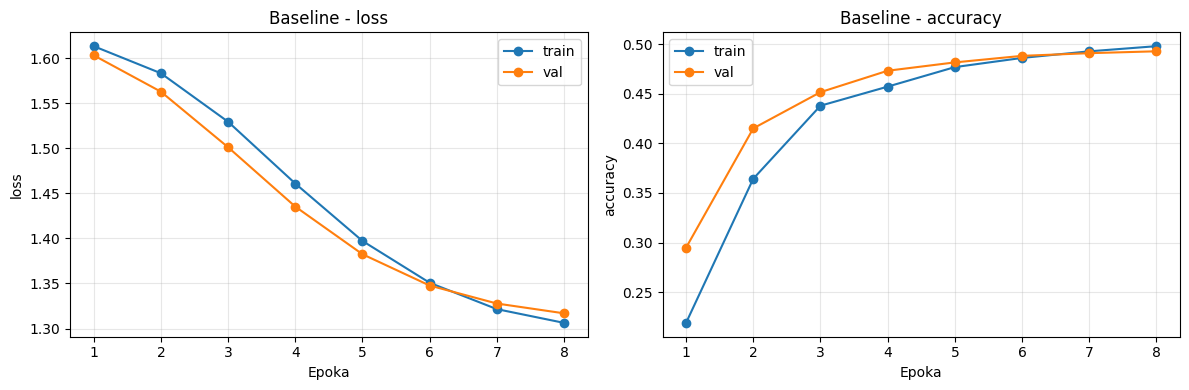

In [26]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train/loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history[f"train/{metric}"], "o-", label="train")
        ax.plot(epochs, history[f"val/{metric}"], "o-", label="val")
        ax.set_xlabel("Epoka")
        ax.set_ylabel(metric)
        ax.set_title(f"{title} - {metric}")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, "Baseline")